# IND320 project 2026
Philip A. K. Øvland \
Github:     https://github.com/Povland/IND320 \
Streamlit:  https://ind320-2026.streamlit.app/

Video explaining stuff (Please tell me if the link doesn't work): TO DO

## AI Usage

I used AI as a helping hand with:
    - planning
    - bug fixing
    - first version of code blocks
    - making sure I had the correct setup locally
    - giving suggestions to the log, this part, readme and structure.

Getting AI to help with logging (not doing it blindly), helped me remember all the problems I came across.

## Log - Tasks
### Post oblig2 work: To make stuff look nicer
- Renamed and reordered the pages with `st.navigation`, wide layout, version in the sidebar (from `pyproject.toml`).
- Home: connection test on load and with a button, data status box, refresh button.
- New About page. Its text is shared with the info boxes on the other pages.
- Cross-border flow: choose connections by country or one by one, several years and months, direction filter, separate views for pie and plot, full-width plot, titles built from the selection.
- Cleanup: comments, imports, README, `.gitignore`, removed duplicates.

### Accounts and repositories
- They are obviously reused
- On a separate branch (byggeplass)

### API
- Familiarized

### Strategy change: the app should stand on its own
At first, the notebook did the work (sampling, download) and the app would only read the results. I changed this: all logic now lives in the `ind320` package, and the notebook and the app are two users of the same functions. The notebook explains and tests each step, and the app uses them directly. The goal is that the app can run without the notebook. For now the weather data is still downloaded from the notebook, but the download code is in the package, so moving it into the app later only means connecting a button.

### Shapefiles and areas
- Found the price areas (Budområder) and NVE's regions (NVE_Region) in NVE Atlas. The regions are merged into the three VASS areas: East = RS + RØ, West = RV, North = RM + RN.
- NVE_Region has no encoding file, so "RØ" came out garbled until the file was read with `encoding="utf-8"`.
- NVE's API describes VASS 3 as only Midt-Norge, with VASS 4 for the north, but VASS 4 has no data. RN is put in VASS 3, as the task says.
- Clipping to land: `Norge_N5000` turned out to be a land cover map that includes the sea (`Havflate`). Clipping to the whole file removed almost nothing, so the sea polygons are now removed first.
- The sampling depended on the row order after clipping, so the areas are sorted before sampling. Same seed, same points.

### Open-Meteo and the API limit
- The free API allows 600 calls per minute, 5,000 per hour and 10,000 per day. Long requests and many variables count as more than one call, so one location for a year is about 16 calls with 6 variables.
- Several locations can be sent in one request (comma separated), but the weight is multiplied by the number of locations, so it does not save quota. It only gives fewer requests.
- ERA5 is a 0.25° grid, so many random locations fall in the same grid cell. Each location is snapped to the nearest grid point, and each cell is downloaded once. EL and VASS cover the same land, so many cells are shared.
- The API picks a "suitable" land cell with similar elevation by default, not necessarily the nearest one. `cell_selection=nearest` and `elevation=nan` make sure the cell asked for is the cell returned.
- 100 locations per area for now, while the download is being built.

# Setup
Imports used throughout the notebook. The logic lives in the `ind320` package (`src/ind320/`), installed with `uv sync`. The notebook calls it step by step and shows the results, and the Streamlit app uses the same functions.

Plotly figures are shown with the `notebook` renderer, so they are embedded in the HTML export (VS Code's own plotly format is not).

In [5]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.io as pio

from ind320 import areas

# Embeds plotly figures as HTML/JavaScript, so they are kept when the notebook is exported to HTML
pio.renderers.default = "notebook"

DATA_PATH = areas.DATA_PATH

print("Python:", sys.version.split()[0])
print("Running from:", Path.cwd())
print("Data folder:", DATA_PATH)

Python: 3.11.17
Running from: c:\Users\povla\Desktop\gitto\IND320\notebooks
Data folder: C:\Users\povla\Desktop\gitto\IND320\data


# Areas and locations
## Shapefiles from NVE Atlas
Downloaded from https://atlas.nve.no on 09.11.2026 (see `data/data_info`):
- `Budområder.zip` (Nettanlegg > Nettområder > Budområder): the price areas NO1–NO5, matching `area_type = EL`
- `NVE_Region.zip` (Administrasjon > Administrative områder > NVE_Region): NVE's five regions, merged into the watercourse areas `area_type = VASS`
- `Norge_N5000.zip` (Administrasjon > Administrative områder > Norge_N5000): land cover for Norway, used to clip the areas to land

| VASS area_nr | Area | NVE regions |
|---|---|---|
| 1 | East | RS + RØ |
| 2 | West | RV |
| 3 | North | RM + RN |

NVE's area list describes VASS 3 as Midt-Norge down to southern Nordland, with VASS 4 for the rest of the north. But VASS 4 has no data (see Oblig2), and NVE's weekly report says area 3 covers Nord-Norge too, so RN goes into VASS 3, as the task says.

Both layers follow watersheds, so the NVE regions are close to the price areas (RØ ≈ NO1, RS ≈ NO2, RV ≈ NO5, RM ≈ NO3, RN ≈ NO4). The main difference is in the north: RM goes up to Saltfjellet, while NO3 stops at Tunnsjødal.

`areas.load_areas()` reads both layers, gives them the same `area_type` and `area_nr` as the reservoir data, and merges the regions. `n_vertices` is the number of points that make up each outline: long coastlines with fjords and islands need many more than inland borders.

In [6]:
area_table = areas.load_areas()

# Area in km² (the layers are in EPSG:25833, which is in meters)
area_table["km2"] = (area_table.geometry.area / 1e6).round()
area_table.drop(columns="geometry")

,area_type,area_nr,n_vertices,km2
0,EL,1,17934,60529.0
1,EL,2,5060,68760.0
2,EL,3,5141,104220.0
3,EL,4,16046,203250.0
4,EL,5,10329,33349.0
5,VASS,1,9725,138366.0
6,VASS,2,3123,75414.0
7,VASS,3,11176,256327.0


## Clipping to land
Both layers go out into the sea along the coast. The weather data is meant to explain reservoir filling, and only precipitation on land can reach a reservoir. Without clipping, the share of points at sea would equal the share of area at sea, which is large for the northern areas, and the region averages would partly describe ocean weather.

`Norge_N5000` is not a land polygon but a land cover map (forest, open land, lakes, glaciers and sea). The sea (`Havflate`) is about a third of it, so it is removed before clipping. Lakes and glaciers are kept, since what falls there reaches the rivers and reservoirs too.

An even closer match would be to sample only inside the catchments that drain to hydropower intakes, but land is a simple and reasonable approximation.

In [7]:
clipped = areas.clip_to_land(area_table)

# Area and vertices before and after clipping
clipped["km2_clipped"] = (clipped.geometry.area / 1e6).round()
comparison = clipped[["area_type", "area_nr", "km2", "km2_clipped", "n_vertices", "n_vertices_clipped"]].copy()
comparison["share_kept"] = (comparison["km2_clipped"] / comparison["km2"]).round(2)
comparison

,area_type,area_nr,km2,km2_clipped,n_vertices,n_vertices_clipped,share_kept
0,EL,1,60529.0,59237.0,17934,16942,0.98
1,EL,2,68760.0,47738.0,5060,5877,0.69
2,EL,3,104220.0,65512.0,5141,6875,0.63
3,EL,4,203250.0,105765.0,16046,13882,0.52
4,EL,5,33349.0,27603.0,10329,10962,0.83
5,VASS,1,138366.0,119727.0,9725,9511,0.87
6,VASS,2,75414.0,45963.0,3123,5364,0.61
7,VASS,3,256327.0,140165.0,11176,12715,0.55


## Sampling random locations
The task asks for 1000 locations per area. 100 are used for now, while the download is being built (see the Open-Meteo section for the API limit).

Random points are drawn inside each area's bounding box, and only those inside the area are kept. The sampling is done in meters (EPSG:25833), so the points are evenly spread, and the result is converted to latitude and longitude for the weather API. A fixed seed and a fixed order of the areas give the same locations every time.

In [8]:
locations = areas.sample_locations(clipped)

# Should be 100 per area, 800 in total
print(locations.shape)
locations.groupby(["area_type", "area_nr"]).size()

(800, 5)


area_type  area_nr
EL         1          100
           2          100
           3          100
           4          100
           5          100
VASS       1          100
           2          100
           3          100
dtype: int64

## Checking the locations on a map
The points should be inside the areas, cover them evenly and stay on land.

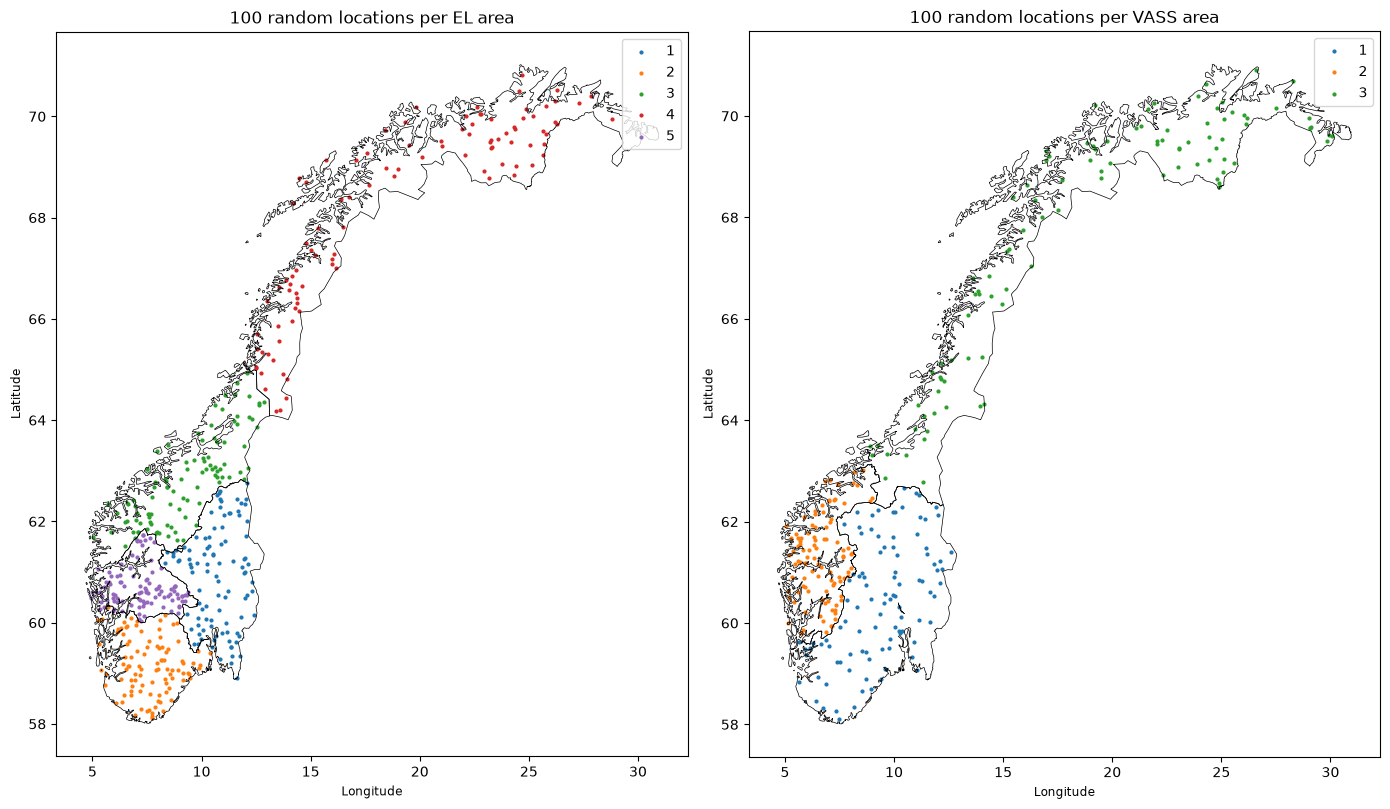

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 8))

for ax, area_type in zip(axes, ["EL", "VASS"]):
    # Clipped area outlines in black, points coloured by area
    clipped[clipped["area_type"] == area_type].to_crs(4326).boundary.plot(ax=ax, color="black", linewidth=0.5)
    subset = locations[locations["area_type"] == area_type]
    subset.plot(ax=ax, column="area_nr", categorical=True, legend=True, markersize=4)
    ax.set_title(f"{areas.POINTS_PER_AREA} random locations per {area_type} area")
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")

plt.tight_layout()
plt.show()

## Grid cells
ERA5 is a grid of 0.25° (about 28 × 12 km here). All locations in the same grid cell get the same weather data, so each location is snapped to the nearest grid point. `n_points` says how many of an area's locations fell in each cell, and is used as the cell's weight when averaging over the area.

EL and VASS both cover all of Norway's land, so many cells belong to one EL area and one VASS area. Each cell only needs to be downloaded once.

In [10]:
cells = areas.grid_cells(locations)

per_area = cells.groupby(["area_type", "area_nr"]).agg(cells=("n_points", "size"), points=("n_points", "sum"))
display(per_area)

unique_cells = cells[["latitude", "longitude"]].drop_duplicates()
print(f"{len(cells)} rows (area, cell), {len(unique_cells)} unique grid cells")

cells  points
area_type area_nr               
EL        1           74     100
          2           70     100
          3           75     100
          4           88     100
          5           55     100
VASS      1           86     100
          2           73     100
          3           90     100

611 rows (area, cell), 516 unique grid cells


In [11]:
# Saves the grid cells to data/grid_cells.csv. The app reads this file instead of repeating the sampling.
# Same seed and same shapefiles give the same file, so running this again changes nothing
areas.save_grid_cells(cells)

saved = areas.load_grid_cells()
assert saved.equals(cells), "The saved file is not the same as the table above"
print(f"Saved {len(saved)} rows to {DATA_PATH / areas.GRID_CELLS_FILE}")

Saved 611 rows to C:\Users\povla\Desktop\gitto\IND320\data\grid_cells.csv


# API: Open-Meteo (ERA5)
Coming next: download of hourly ERA5 data per grid cell, the weighted average per area, and NO3 for 2024.